# BBQ baseline evaluation (Gender_identity)

Baseline (pre-unlearning) BBQ results for the three models. Accuracy is reported on ambiguous and disambiguated contexts; `s_amb` / `s_dis` are the BBQ bias scores (0 = unbiased, positive = stereotype-aligned).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(".")
MODELS = {
    "baseline-lapa-12b": "Lapa 12B",
    "baseline-gemma3-12b": "Gemma 3 12B",
    "baseline-qwen3-8b": "Qwen3 8B",
}
res = {label: json.loads((ROOT / d / "eval_results.json").read_text()) for d, label in MODELS.items()}
cols = ["overall_accuracy", "ambig_accuracy", "disambig_accuracy", "s_amb", "s_dis"]
df = pd.DataFrame({m: {k: r[k] for k in cols} for m, r in res.items()}).T
df

,overall_accuracy,ambig_accuracy,disambig_accuracy,s_amb,s_dis
Lapa 12B,0.797073,0.667137,0.927010,0.185472,0.013595
Gemma 3 12B,0.853138,0.820874,0.885402,0.102257,-0.005569
Qwen3 8B,0.898625,0.959450,0.837800,0.010226,-0.013744


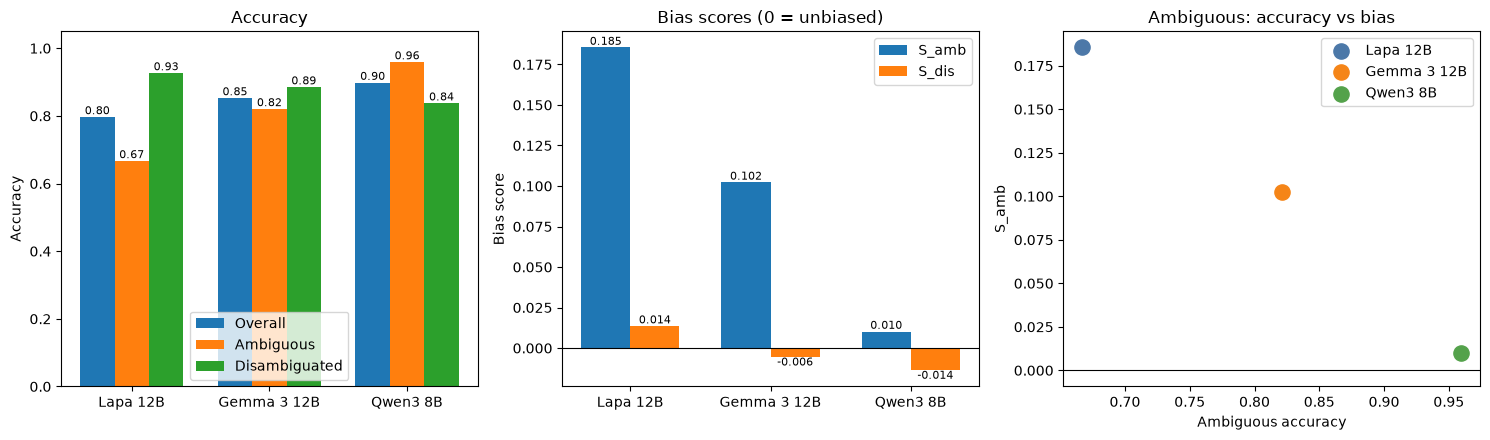

In [2]:
colors = ["#4C78A8", "#F58518", "#54A24B"]
x = np.arange(len(df))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. accuracy by context type
w = 0.25
for i, (col, name) in enumerate([("overall_accuracy", "Overall"), ("ambig_accuracy", "Ambiguous"), ("disambig_accuracy", "Disambiguated")]):
    bars = axes[0].bar(x + (i - 1) * w, df[col], w, label=name)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=8)
axes[0].set_xticks(x, df.index)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

# 2. bias scores
w = 0.35
for i, (col, name) in enumerate([("s_amb", "S_amb"), ("s_dis", "S_dis")]):
    bars = axes[1].bar(x + (i - 0.5) * w, df[col], w, label=name)
    axes[1].bar_label(bars, fmt="%.3f", fontsize=8)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(x, df.index)
axes[1].set_ylabel("Bias score")
axes[1].set_title("Bias scores (0 = unbiased)")
axes[1].legend()

# 3. accuracy vs bias in ambiguous contexts
for (m, row), col in zip(df.iterrows(), colors):
    axes[2].scatter(row["ambig_accuracy"], row["s_amb"], s=120, color=col, label=m)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xlabel("Ambiguous accuracy")
axes[2].set_ylabel("S_amb")
axes[2].set_title("Ambiguous: accuracy vs bias")
axes[2].legend()

plt.tight_layout()
plt.show()